# 답지 적중률 ablation: 무엇을 바꾸면 "이번 주 원인"을 더 맞히는가

`PCMCI-LPCMCI.ipynb`·`RCBNB-MB.ipynb` 의 결론은 "그래프 탐색을 더 튜닝해도 주별 귀속 top-3 적중률은 0.15 ~ 0.26 에서 오르지 않는다"였다.
이 노트북은 적중률을 실제로 올릴 수 있는 축을 한 번에 하나씩 바꿔 본다. 데이터·변환·답지·채점은 같은 `analysis/causal_common.py` 를 쓴다.

**두 트랙을 섞지 않는다.**
- **트랙 ① 데이터만**: 답지에서 배운 정보를 쓰지 않는다. 입력 표현·귀속 규칙·변수 선택만 바꾼다.
- **트랙 ② 빈도 사전확률**: 그 주 이전 답지에서 자주 인용된 변수에 가중을 준다. 인과 탐색이 아니라 답지에서 배우는 것이다.

**평가 규약 (모든 실험 공통)**
- 지표: 주별 귀속 top-1 · top-3 적중률. 분모는 인용 변수가 패널에 있는 답지 주. 우연 = 무작위 k 개의 기대 적중률.
- 기간: 답지의 처음 26주(2023-01 ~ 2023-06)는 빈도 사전확률을 채우는 데만 쓰고 채점하지 않는다.
  **선택 구간 2023-07 ~ 2024-12**(79주), **확인 구간 2025-01 ~ 2026-10**(95주). 무엇을 채택할지는 선택 구간의 top-3(세 원자재 평균)만으로 정한다.
  두 구간 모두 앞 분석에서 전체 기간 합계로 본 적이 있다 — 미사용 holdout 이 아니다.
- 계수(ρ, β)와 그래프는 확인 구간을 뺀 주(2025-01 이전)로만 적합한다.
- 부모 대비 차이는 같은 주끼리 짝지은 4주 블록 bootstrap 95% 구간과 함께 적는다. 구간이 0 을 포함하면 차이가 있다고 읽지 않는다.

**트랙 ① 의 단계** — 같은 축의 후보는 같은 부모에서 한 축만 바꾼다. 선택 구간에서 부모보다 나은 후보만 채택되어 다음 단계의 부모가 된다.

| 실험 | 바꾸는 축 | 내용 |
| --- | --- | --- |
| `d0_regress` | (기준) | 전체 변수 같은 주 회귀의 기여 β·x |
| `d1_marginal` | 귀속 규칙 | 변수별 주변 기여 ρ_i·x_i — 함께 움직이는 변수끼리 계수를 깎지 않는다 |
| `d2_event` | 입력 표현 | 계단형(월·분기) 변수 = 발표 주 사건: 발표 지연이 반영된 값이 바뀐 주에만 표준화한 변화, 나머지 주는 0 |
| `d3_same_sign` | 사후 필터 | 그 주 가격과 같은 방향으로 민 기여만 남긴다(사후 설명이라 그 주 가격을 쓴다) |
| `d4_percentile` | 척도 | 점수 = 그 변수의 움직인 주들 안에서의 \|기여\| 분위 — 발표 사건과 주간 변수를 같은 척도에 놓는다 |
| `d5_graph` | 변수 선택 | PCMCI+(같은 주 방향 가정 유지)가 찾은 가격의 부모 항만 쓴다 |
| `d6_precip8`, `d6_precip13` | 강수 표현 (커피) | 강수 평년 대비 편차의 누적 창 4주 → 8주, 13주 |

**트랙 ①′ 발표 서프라이즈** (4절) — 트랙 ① 의 채택 설정에서 출발해, 답지가 인용하는 발표 지표 12개를 실제 발표 이력(발표일·실제치·시장 예상치)으로 바꾼다. 답지 정보는 쓰지 않는다.

| 실험 | 부모 | 바꾸는 축 | 내용 |
| --- | --- | --- | --- |
| `e1_release_week` | 트랙 ① 채택 설정 | 발표 주 정렬 | 사건을 실제 발표 주에 놓는다. 크기 = 직전 발표 대비 실제치 변화(기대 = 지난번 값) |
| `e2_surprise` | e1 | 크기 정의 | 크기 = 실제 − 시장 예상(기대 = 컨센서스) |
| `e3_percentile` | e2 | 척도 | 점수 = 그 변수의 움직인 주들 안에서의 \|기여\| 분위 |
| `p2_c*` | `p0_prior` | 트랙 ② | 빈도 사전확률 × (c + 위에서 고른 점수) |

**트랙 ①″ 커피 공급 변수** (5절) — 커피만. 답지가 기상·수출을 인용하는 모습(지난주 강우의 평년 대비, 강우 예보, 전년 동월 대비 수출)에 입력 표현을 맞춘다.
표현을 답지 문구를 읽고 골랐으므로 답지에서 배운 정보가 섞여 있다. 채택은 선택 구간 숫자로만 한다.

| 실험 | 부모 | 바꾸는 축 | 내용 |
| --- | --- | --- | --- |
| `c1_last_week` | 트랙 ① 채택 설정 | 강수 표현 | 강수 열 = 지난주 1주 강우의 평년 대비 편차. 귀속 규칙은 그대로(ρ·x) |
| `c2_salience` | c1 | 귀속 척도 | 점수 = 그 변수 자신의 \|값\| 분위(이번 주에 얼마나 이례적인가). ρ 의 크기에 기대지 않는다 |
| `c3_weather_bundle` | c2 | 기상 표현 묶음 | 기상 변수의 점수 = 표현들의 분위 중 최댓값: 지난주·같은 주·다음 주(예보 대용, 미래 값)·8주 평균, 미나스는 최고·최저기온 추가 |
| `c4_yoy` | c3 | 계단형 변화 정의 | 수출·생산·재고의 사건 크기 = 52주 전 대비 변화 |
| `p3_c*` | `p0_prior` | 트랙 ② | 빈도 사전확률 × (c + 위에서 고른 커피 점수) |

이미 본 기간을 탐색하는 분석이다. 예측 성능 평가가 아니다.

In [1]:
import functools, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

from causal_common import (KEY, RELEASE_FILE, RELEASES, SERIES, attribution, event_panel, lagged_values, load_key, make_panel,
                           paired_block_ci, pcmci_parents, prior_scores, raw, release_panel, score_weeks, sinks, weather_views, week_hits)

warnings.filterwarnings("ignore")
BURN = 26               # 답지의 처음 26주: 빈도 사전확률을 채우는 데만 쓴다
CONFIRM = "2025-01-01"  # 이 주부터 확인 구간. 계수·그래프 적합에서도 뺀다
K = 3                   # 채택 기준: 선택 구간 top-3 의 세 원자재 평균

keys = {s: load_key(s) for s in SERIES}
PERIODS = {"선택": lambda k: k.iloc[BURN:].loc[:"2024-12-31"], "확인": lambda k: k.loc[CONFIRM:]}


@functools.lru_cache(None)
def panel(s, precip=4):
    X, info = make_panel(s, precip)
    return X, info, event_panel(s, X, info)


for s in SERIES:
    X, info, _ = panel(s)
    weeks = {per: len(cut(keys[s])) for per, cut in PERIODS.items()}
    print(f"{s}: 변수 {X.shape[1] - 1}개 (계단형 {info.변환.str.startswith('계단형').sum()}개), 답지 주 수 {weeks}")

coffee: 변수 19개 (계단형 9개), 답지 주 수 {'선택': 79, '확인': 95}
copper: 변수 31개 (계단형 19개), 답지 주 수 {'선택': 79, '확인': 95}


gold: 변수 24개 (계단형 15개), 답지 주 수 {'선택': 79, '확인': 95}


## 1. 발표 주 정렬 — 계단형 변수는 언제 인용되는가

답지가 계단형 변수(CPI·고용·생산 추정 등)를 인용한 (주, 변수) 건마다, 그 주에 값이 실제로 바뀌었는지 센다.
- 지연 없음: 지금까지의 패널. 월·분기 값이 기준 기간의 끝 주에 놓인다.
- 지연 반영: 발표 지연을 적용한 값(`exogenous.parquet`). 값이 바뀐 주 = 그 값이 알려진 주.
- 기준 확률: 계단형 변수가 아무 주에나 바뀌어 있을 확률(2023 이후).

In [2]:
rows = []
for s in SERIES:
    X, info, E = panel(s)
    step = set(info.변수[info.변환.str.startswith("계단형")])
    nolag = raw[raw.series == s].pivot(index="week", columns="col_name", values="value").reindex(X.index)
    lagged = lagged_values(s).reindex(X.index)
    pairs = [(w, c) for w, cs in keys[s].cited.items() if w in X.index for c in cs & step]
    changed = lambda F, near: np.mean([(F[c].diff().fillna(0) != 0).rolling(1 + 2 * near, center=True, min_periods=1).max()[w] for w, c in pairs])
    rows.append({"원자재": s, "계단형 인용 건": len(pairs),
                 "지연 없음: 그 주": changed(nolag, 0), "지연 반영: 그 주": changed(lagged, 0), "지연 반영: ±1주": changed(lagged, 1),
                 "기준 확률": (lagged[sorted(step)].diff().fillna(0) != 0)["2023":].mean().mean()})
pd.DataFrame(rows).round(2)

,원자재,계단형 인용 건,지연 없음: 그 주,지연 반영: 그 주,지연 반영: ±1주,기준 확률
0,coffee,58,0.26,0.24,0.50,0.17
1,copper,60,0.25,0.47,0.82,0.19
2,gold,62,0.21,0.61,0.87,0.19


## 2. 트랙 ① — 데이터만

`score` 가 설정 하나를 주 × 변수 점수로 바꾼다. 점수의 부호 = 그 변수가 가격을 민 방향, 크기 = 순위를 정하는 값.

In [3]:
BASE = dict(rule="regress", event=False, same_sign=False, percentile=False, graph=False, precip=4)
STEPS = [("귀속 규칙", {"d1_marginal": dict(rule="marginal")}),
         ("입력 표현", {"d2_event": dict(event=True)}),
         ("사후 필터", {"d3_same_sign": dict(same_sign=True)}),
         ("척도", {"d4_percentile": dict(percentile=True)}),
         ("변수 선택", {"d5_graph": dict(graph=True)}),
         ("강수 표현(커피)", {"d6_precip8": dict(precip=8), "d6_precip13": dict(precip=13)})]


@functools.lru_cache(None)
def _score(s, rule, event, same_sign, percentile, graph, precip, release=None):
    X, info, E = panel(s, precip)
    P = release_panel(E, release, CONFIRM) if release else E if event else X  # release: 4절(트랙 ①′)
    p, fit = X.price, pd.Series(X.index < CONFIRM, index=X.index)
    D = P.drop(columns="price").fillna(0)
    terms = pcmci_parents(P[fit], sinks(X, info)) if graph else {(c, 0) for c in D}
    if rule == "regress":
        c = attribution(P, terms, fit)
    else:
        c = pd.DataFrame(0.0, index=X.index, columns=D.columns)
        for v, t in terms:
            x = D[v].shift(t).fillna(0)
            c[v] += x * x[fit].corr(p[fit])
        c = c.fillna(0)
    if percentile:
        c = c.abs().where(c != 0).rank(pct=True).fillna(0) * np.sign(c)
    if same_sign:
        c = c.where(np.sign(c).values == np.sign(p.fillna(0)).values[:, None], 0)
    return c


def score(s, cfg):
    return _score(s, **{**cfg, "precip": cfg["precip"] if s == "coffee" else 4})  # 강수 변수는 커피에만 있다


def hits(get, s, per, k=K):
    return week_hits(get(s), panel(s)[0], PERIODS[per](keys[s]), k)


def pooled(get, per="선택"):
    return np.mean([hits(get, s, per).mean() for s in SERIES])


def table(runs):
    """runs = {실험: (부모 이름, 점수 함수 s → 주 × 변수, 채택 여부)} → 실험 × 원자재 표."""
    rows = []
    for name, (parent, get, adopted) in runs.items():
        for s in [*SERIES, "평균"]:
            row = {"실험": name, "부모": parent or "", "채택": {True: "채택", False: "", None: "(기준)"}[adopted], "원자재": s}
            for per in PERIODS:
                for k in (1, 3):
                    row[f"{per} top{k}"] = np.mean([hits(get, x, per, k).mean() for x in (SERIES if s == "평균" else [s])])
                if parent and s != "평균":
                    d, lo, hi = paired_block_ci(hits(get, s, per), hits(runs[parent][1], s, per))
                    row[f"{per} top3 − 부모"] = f"{d:+.2f} [{lo:+.2f}, {hi:+.2f}]"
            rows.append(row)
    return pd.DataFrame(rows).fillna("")


cur_name, cur = "d0_regress", BASE
track1 = {cur_name: (None, functools.partial(score, cfg=BASE), None)}
configs = {cur_name: BASE}
for axis, cands in STEPS:
    configs |= {name: cur | change for name, change in cands.items()}
    best = max(cands, key=lambda n: pooled(functools.partial(score, cfg=configs[n])))
    better = pooled(functools.partial(score, cfg=configs[best])) > pooled(functools.partial(score, cfg=cur))
    for name in cands:
        track1[name] = (cur_name, functools.partial(score, cfg=configs[name]), better and name == best)
    if better:
        cur_name, cur = best, configs[best]
print(f"채택된 설정: {cur_name} = {cur}")
t1 = table(track1)
t1.round(3)

채택된 설정: d6_precip8 = {'rule': 'marginal', 'event': True, 'same_sign': False, 'percentile': False, 'graph': False, 'precip': 8}


,실험,부모,채택,원자재,선택 top1,선택 top3,확인 top1,확인 top3,선택 top3 − 부모,확인 top3 − 부모
0,d0_regress,,(기준),coffee,0.045,0.242,0.088,0.300,,
1,d0_regress,,(기준),copper,0.032,0.274,0.056,0.213,,
2,d0_regress,,(기준),gold,0.104,0.299,0.154,0.275,,
3,d0_regress,,(기준),평균,0.061,0.272,0.099,0.263,,
4,d1_marginal,d0_regress,채택,coffee,0.091,0.212,0.100,0.288,"-0.03 [-0.09, +0.05]","-0.01 [-0.12, +0.07]"
5,d1_marginal,d0_regress,채택,copper,0.065,0.242,0.079,0.247,"-0.03 [-0.12, +0.05]","+0.03 [-0.02, +0.10]"
6,d1_marginal,d0_regress,채택,gold,0.182,0.390,0.121,0.330,"+0.09 [+0.00, +0.19]","+0.05 [-0.03, +0.14]"
7,d1_marginal,d0_regress,채택,평균,0.112,0.281,0.100,0.288,,
8,d2_event,d1_marginal,채택,coffee,0.076,0.167,0.038,0.225,"-0.05 [-0.15, +0.05]","-0.06 [-0.19, +0.07]"
9,d2_event,d1_marginal,채택,copper,0.065,0.274,0.079,0.247,"+0.03 [+0.00, +0.08]","+0.00 [+0.00, +0.00]"


### 기준선

같은 주들에서의 우연 기준선과 빈도 기준선(`p0_prior`, 3절). 트랙 ① 의 숫자는 이 둘과 함께 읽는다.

In [4]:
priors = {s: prior_scores(panel(s)[0], keys[s]) for s in SERIES}  # 그 주 이전 답지 주들의 인용 횟수
p0 = lambda s: priors[s]
base_rows = []
for s in SERIES:
    for per, cut in PERIODS.items():
        sc = score_weeks(p0(s), panel(s)[0], cut(keys[s]))
        base_rows.append({"원자재": s, "구간": per, "답지 주 수": sc["답지 주 수"], "우연 top1": sc["top1 우연"], "우연 top3": sc["top3 우연"],
                          "빈도 top1": sc["top1"], "빈도 top3": sc["top3"]})
baselines = pd.DataFrame(base_rows)
baselines.round(3)

,원자재,구간,답지 주 수,우연 top1,우연 top3,빈도 top1,빈도 top3
0,coffee,선택,66,0.053,0.158,0.182,0.561
1,coffee,확인,80,0.053,0.158,0.338,0.475
2,copper,선택,62,0.032,0.097,0.177,0.387
3,copper,확인,89,0.032,0.097,0.202,0.427
4,gold,선택,77,0.042,0.125,0.208,0.377
5,gold,확인,91,0.042,0.125,0.176,0.451


## 3. 트랙 ② — 답지 인용 빈도를 사전확률로

- `p0_prior`: 그 주 **이전** 답지 주들에서 그 변수가 인용된 횟수. 그 주의 답은 쓰지 않는다. 매주 거의 같은 변수를 찍는다 — 넘어야 할 기준선.
- `p1_c*`: 사전확률 × (c + 트랙 ① 에서 채택된 점수의 크기). 점수는 주마다 가장 큰 값이 1 이 되게 나눈다. c 후보는 0, 0.5, 1 로 고정.
  c = 0 이면 그 주에 움직이지 않은 변수는 빠지고, c 가 클수록 사전확률 쪽으로 기운다.

In [5]:
chosen = functools.partial(score, cfg=cur)


def mixed(s, c, get=None):
    a = (get or chosen)(s).reindex(priors[s].index).abs()
    return priors[s] * (c + a.div(a.max(axis=1).replace(0, np.nan), axis=0).fillna(0))


cands = {f"p1_c{c}": functools.partial(mixed, c=c) for c in (0, 0.5, 1)}
best = max(cands, key=lambda n: pooled(cands[n]))
better = pooled(cands[best]) > pooled(p0)
track2 = {"p0_prior": (None, p0, None)} | {n: ("p0_prior", g, better and n == best) for n, g in cands.items()}
print(f"선택 구간에서 가장 나은 후보: {best} ({'p0_prior 보다 높음' if better else 'p0_prior 를 넘지 못함'})")
t2 = table(track2)
t2.round(3)

선택 구간에서 가장 나은 후보: p1_c0.5 (p0_prior 보다 높음)


,실험,부모,채택,원자재,선택 top1,선택 top3,확인 top1,확인 top3,선택 top3 − 부모,확인 top3 − 부모
0,p0_prior,,(기준),coffee,0.182,0.561,0.338,0.475,,
1,p0_prior,,(기준),copper,0.177,0.387,0.202,0.427,,
2,p0_prior,,(기준),gold,0.208,0.377,0.176,0.451,,
3,p0_prior,,(기준),평균,0.189,0.441,0.239,0.451,,
4,p1_c0,p0_prior,,coffee,0.182,0.333,0.212,0.412,"-0.23 [-0.35, -0.09]","-0.06 [-0.15, +0.04]"
5,p1_c0,p0_prior,,copper,0.258,0.419,0.213,0.393,"+0.03 [-0.08, +0.15]","-0.03 [-0.10, +0.02]"
6,p1_c0,p0_prior,,gold,0.221,0.416,0.176,0.418,"+0.04 [-0.06, +0.15]","-0.03 [-0.11, +0.03]"
7,p1_c0,p0_prior,,평균,0.220,0.389,0.201,0.408,,
8,p1_c0.5,p0_prior,채택,coffee,0.182,0.530,0.250,0.475,"-0.03 [-0.09, +0.03]","+0.00 [+0.00, +0.00]"
9,p1_c0.5,p0_prior,채택,copper,0.258,0.419,0.202,0.404,"+0.03 [-0.05, +0.12]","-0.02 [-0.08, +0.02]"


## 4. 트랙 ①′ — 발표 서프라이즈

답지가 인용하는 발표 지표 12개(`RELEASES`)를 Investing.com 의 발표 이력으로 바꾼다. 발표 한 건마다 발표일·실제치·시장 예상치가 있다.
먼저 정렬을 본다 — 발표 지표 인용 건 가운데 실제 발표 주가 인용 주와 같은 비율, 그리고 그 주의 발표가 예상과 달랐던 비율(같았다면 서프라이즈가 0 이라 순위에 들 수 없다).

In [6]:
rel = pd.read_parquet(RELEASE_FILE)
rel["week"] = rel.dt.dt.to_period("W-SUN").dt.end_time.dt.normalize()
r = rel.pivot_table(index=["event", "week"], columns="field", values="value", aggfunc="last")
print(rel[rel.field == "actual"].groupby("event").dt.agg(첫_발표="min", 마지막_발표="max", 발표_수="count").to_string(), "\n")

rows = []
for s in SERIES:
    X, info, E = panel(s)
    L = lagged_values(s).reindex(X.index)
    pairs = [(w, c) for w, cs in keys[s].iloc[BURN:].cited.items() if w in X.index for c in cs & set(RELEASES) & set(X.columns)]
    if not pairs:
        continue
    near = lambda w, c, k: any((e, w + pd.Timedelta(weeks=d)) in r.index for e in RELEASES[c] for d in range(-k, k + 1))
    differ = lambda w, c: any((e, w) in r.index and r.loc[(e, w), "actual"] != r.loc[(e, w), "forecast"] for e in RELEASES[c])
    rows.append({"원자재": s, "발표 지표 인용 건": len(pairs),
                 "지연 추정: 그 주": np.mean([L[c].diff().fillna(0)[w] != 0 for w, c in pairs]),
                 "실제 발표: 그 주": np.mean([near(w, c, 0) for w, c in pairs]), "실제 발표: ±1주": np.mean([near(w, c, 1) for w, c in pairs]),
                 "그 주 발표가 예상과 달랐다": np.mean([differ(w, c) for w, c in pairs])})
pd.DataFrame(rows).round(2)

                                      첫_발표     마지막_발표  발표_수
event                                                      
Com_Econ_CN_gdp_yoy             2011-01-20 2026-10-19    63
Com_Econ_CN_industrial_prod_yoy 2010-12-11 2026-10-19   176
Com_Econ_CN_pmi_mfg             2012-04-01 2026-10-31   176
Com_Econ_US_core_cpi_mom        2008-02-20 2026-10-14   223
Com_Econ_US_cpi_mom             2008-03-14 2026-10-14   222
Com_Econ_US_gdp_qoq             2008-02-28 2026-10-29   222
Com_Econ_US_ism_pmi             2008-03-03 2026-11-02   225
Com_Econ_US_ism_pmi_nonmfg      2008-03-05 2026-11-04   225
Com_Econ_US_nonfarm_payrolls    2008-03-07 2026-11-06   224
Com_Econ_US_ppi_yoy             2012-05-11 2026-10-15   173
Com_Econ_US_retail_sales_mom    2008-02-13 2026-10-15   224
Com_Econ_US_unemployment        2008-08-01 2026-11-06   219 



,원자재,발표 지표 인용 건,지연 추정: 그 주,실제 발표: 그 주,실제 발표: ±1주,그 주 발표가 예상과 달랐다
0,copper,26,0.54,0.92,1.00,0.88
1,gold,40,0.70,0.95,0.98,0.95


세 단계는 채택 여부와 상관없이 e1 → e2 → e3 로 잇는다(각 줄의 차이 = 바로 앞 단계 대비).
선택 구간 평균이 트랙 ① 채택 설정보다 높은 것 가운데 가장 높은 하나에 채택 표시를 한다.

In [7]:
CHAIN = {"e1_release_week": dict(release="change"), "e2_surprise": dict(release="surprise"),
         "e3_percentile": dict(release="surprise", percentile=True)}
configs |= {n: cur | change for n, change in CHAIN.items()}
gets = {cur_name: chosen} | {n: functools.partial(score, cfg=configs[n]) for n in CHAIN}
best1 = max(gets, key=lambda n: pooled(gets[n]))  # 동점이면 앞의 것 = 트랙 ① 채택 설정
track1b = {cur_name: (None, chosen, None)} | {n: (parent, gets[n], n == best1) for n, parent in zip(CHAIN, [cur_name, *CHAIN])}
chosen2 = gets[best1]
print(f"선택 구간에서 가장 나은 설정: {best1}" + ("" if best1 != cur_name else " (발표 이력 단계는 채택되지 않았다)"))
t1b = table(track1b)
t1b.round(3)

선택 구간에서 가장 나은 설정: e2_surprise


,실험,부모,채택,원자재,선택 top1,선택 top3,확인 top1,확인 top3,선택 top3 − 부모,확인 top3 − 부모
0,d6_precip8,,(기준),coffee,0.091,0.197,0.062,0.188,,
1,d6_precip8,,(기준),copper,0.065,0.274,0.079,0.247,,
2,d6_precip8,,(기준),gold,0.182,0.416,0.121,0.341,,
3,d6_precip8,,(기준),평균,0.112,0.296,0.087,0.258,,
4,e1_release_week,d6_precip8,,coffee,0.091,0.197,0.062,0.188,"+0.00 [+0.00, +0.00]","+0.00 [+0.00, +0.00]"
5,e1_release_week,d6_precip8,,copper,0.065,0.274,0.079,0.247,"+0.00 [+0.00, +0.00]","+0.00 [+0.00, +0.00]"
6,e1_release_week,d6_precip8,,gold,0.182,0.403,0.121,0.330,"-0.01 [-0.04, +0.00]","-0.01 [-0.03, +0.00]"
7,e1_release_week,d6_precip8,,평균,0.112,0.291,0.087,0.255,,
8,e2_surprise,e1_release_week,채택,coffee,0.091,0.197,0.062,0.188,"+0.00 [+0.00, +0.00]","+0.00 [+0.00, +0.00]"
9,e2_surprise,e1_release_week,채택,copper,0.065,0.290,0.079,0.247,"+0.02 [+0.00, +0.05]","+0.00 [+0.00, +0.00]"


같은 점수를 빈도 사전확률에 섞는다(트랙 ② 와 같은 식, c 후보도 같다). 위에서 채택된 단계가 없어도 서프라이즈가 사전확률 위에서 보태는지는 따로 봐야 하므로 `e2_surprise` 를 섞는다.

In [8]:
cands2 = {f"p2_c{c}": functools.partial(mixed, c=c, get=gets["e2_surprise"]) for c in (0, 0.5, 1)}
best2 = max(cands2, key=lambda n: pooled(cands2[n]))
better2 = pooled(cands2[best2]) > pooled(p0)
track2b = {"p0_prior": (None, p0, None)} | {n: ("p0_prior", g, better2 and n == best2) for n, g in cands2.items()}
print(f"선택 구간에서 가장 나은 후보: {best2} ({'p0_prior 보다 높음' if better2 else 'p0_prior 를 넘지 못함'})")
t2b = table(track2b)
t2b.round(3)

선택 구간에서 가장 나은 후보: p2_c0.5 (p0_prior 보다 높음)


,실험,부모,채택,원자재,선택 top1,선택 top3,확인 top1,확인 top3,선택 top3 − 부모,확인 top3 − 부모
0,p0_prior,,(기준),coffee,0.182,0.561,0.338,0.475,,
1,p0_prior,,(기준),copper,0.177,0.387,0.202,0.427,,
2,p0_prior,,(기준),gold,0.208,0.377,0.176,0.451,,
3,p0_prior,,(기준),평균,0.189,0.441,0.239,0.451,,
4,p2_c0,p0_prior,,coffee,0.182,0.333,0.212,0.412,"-0.23 [-0.35, -0.09]","-0.06 [-0.15, +0.04]"
5,p2_c0,p0_prior,,copper,0.258,0.452,0.213,0.393,"+0.06 [-0.05, +0.19]","-0.03 [-0.10, +0.02]"
6,p2_c0,p0_prior,,gold,0.221,0.442,0.176,0.418,"+0.06 [-0.04, +0.17]","-0.03 [-0.10, +0.03]"
7,p2_c0,p0_prior,,평균,0.220,0.409,0.201,0.408,,
8,p2_c0.5,p0_prior,채택,coffee,0.182,0.530,0.250,0.475,"-0.03 [-0.09, +0.03]","+0.00 [+0.00, +0.00]"
9,p2_c0.5,p0_prior,채택,copper,0.258,0.435,0.202,0.404,"+0.05 [-0.03, +0.14]","-0.02 [-0.08, +0.02]"


### 사후 진단 — 왜 발표 지표는 순위에 들지 못하는가

규약에 없던 확인이다(결과를 본 뒤에 추가했다). 채택에는 쓰지 않는다.
- 표: 인용이 3주 이상인 발표 지표마다, 발표 주들에서 서프라이즈와 그 주 가격·2년물 금리 변화의 상관(2025-01 이전), 발표 주의 \|기여\| 중앙값.
  "문턱" = 그 원자재에서 top-3 에 들려면 넘어야 하는 값(주마다 세 번째로 큰 \|기여\|의 중앙값).
- 아래 두 줄: 척도를 바꿔도 같은지 본다. 강건 척도 = 표준편차 대신 중앙절대값(2020년 고용 서프라이즈 몇 건이 표준편차를 정한다),
  β·x = 상관 대신 단변량 회귀 계수(발표가 없는 주가 0 인 열은 ρ·x 가 기여를 작게 잡는다).

In [9]:
Y2 = "Com_Home_Treasury_Gov_Daily_Treasury_Par_Yield_Curve_Rates_2_Year_Treasury"
rows, lines = [], []
for s in ("copper", "gold"):
    X, info, E = panel(s)
    p, fit, key = X.price, X.index < CONFIRM, keys[s]
    for label, robust in (("표준편차", False), ("강건 척도", True)):
        D = release_panel(E, "surprise", CONFIRM, robust=robust).drop(columns="price").fillna(0)
        rules = {"ρ·x": D * D[fit].corrwith(p[fit]), "β·x": D * D[fit].apply(lambda x: x.cov(p[fit]) / x.var())}
        for rule, c in rules.items():
            c = c.fillna(0)
            if (label, rule) == ("표준편차", "ρ·x"):  # = e2_surprise
                bar = c.abs().apply(lambda week: week.nlargest(K).iloc[-1], axis=1)[fit].median()
                for col in [x for x in RELEASES if x in D and key.iloc[BURN:].cited.map(lambda v: x in v).sum() >= 3]:
                    ev = (D[col] != 0) & fit
                    rows.append({"원자재": s, "변수": col[:36], "인용 주": key.iloc[BURN:].cited.map(lambda v: col in v).sum(), "발표 주 수": ev.sum(),
                                 "상관: 가격": D.loc[ev, col].corr(p[ev]), "상관: 2년물": D.loc[ev, col].corr(X.loc[ev, Y2]),
                                 "|기여| 중앙값": c.loc[D[col] != 0, col].abs().median(), "문턱": bar})
            top3 = {per: week_hits(c, X, cut(key), K).mean() for per, cut in PERIODS.items()}
            lines.append({"원자재": s, "척도": label, "귀속": rule, "선택 top3": top3["선택"], "확인 top3": top3["확인"]})
print(pd.DataFrame(rows).round(3).to_string(index=False), "\n")
pd.DataFrame(lines).round(3)

   원자재                                   변수  인용 주  발표 주 수  상관: 가격  상관: 2년물  |기여| 중앙값    문턱
copper         Com_Econ_US_nonfarm_payrolls     8     119   0.186    0.056     0.005 0.159
copper    Com_BLS_CPI_All_Items_US_SA_Index     6      98  -0.054    0.234     0.017 0.159
copper                  Com_Econ_CN_pmi_mfg     3     106   0.099    0.371     0.011 0.159
copper                  Com_Econ_CN_gdp_yoy     3      29   0.324   -0.134     0.048 0.159
copper      Com_Econ_CN_industrial_prod_yoy     3     108   0.367    0.050     0.052 0.159
  gold         Com_Econ_US_nonfarm_payrolls    11     119  -0.126    0.056     0.005 0.174
  gold    Com_BLS_CPI_All_Items_US_SA_Index    17      98  -0.173    0.234     0.058 0.174
  gold                  Com_Econ_US_ppi_yoy     3     105  -0.095    0.229     0.045 0.174
  gold Com_Econ_US_real_gdp_qoq_annual_rate     5      95   0.006    0.061     0.001 0.174 



,원자재,척도,귀속,선택 top3,확인 top3
0,copper,표준편차,ρ·x,0.290,0.247
1,copper,표준편차,β·x,0.290,0.247
2,copper,강건 척도,ρ·x,0.290,0.247
3,copper,강건 척도,β·x,0.290,0.247
4,gold,표준편차,ρ·x,0.403,0.330
5,gold,표준편차,β·x,0.403,0.341
6,gold,강건 척도,ρ·x,0.403,0.319
7,gold,강건 척도,β·x,0.403,0.341


## 5. 트랙 ①″ — 커피 공급 변수

커피의 빈틈은 공급 변수다(미나스 강수 47주 인용, top-3 에 든 비율 0.19). 먼저 입력을 본다.
- 위 표: 답지 문구가 "미나스 강우 평년 N%"라고 적은 주마다, 우리 강수 자료(NASA 격자 한 점)의 같은 주·지난주 값(평년 대비 %).
- 아래 표: 강수·기온 표현별로 그 주 가격과의 상관(2025-01 이전). 수확기(5 ~ 8월)와 그 밖을 나눠 본다 — 답지는 수확기의 비를 "수확 지연"(상승)으로, 그 밖의 비를 "가뭄 완화"(하락)로 적는다.

In [10]:
txt = pd.read_excel(KEY, sheet_name=SERIES["coffee"]).dropna(subset=["주 일요일"]).set_index("주 일요일")
quoted = (txt["원인 / 요인"].fillna("") + " " + txt["보조 요인"].fillna("")).str.extract(r"미나스[^\d]{0,12}평년 (\d+)%")[0].dropna().astype(float)
MINAS = "nasa_power_daily_minas_br_precip"
wk = raw[(raw.series == "coffee") & (raw.col_name == MINAS)].set_index("week").value
pct = 100 * wk / wk.groupby(wk.index.isocalendar().week.values).transform("mean")
cmp = pd.DataFrame({"답지 %": quoted, "NASA 같은 주 %": pct.reindex(quoted.index), "NASA 지난주 %": pct.shift(1).reindex(quoted.index)})
print(cmp.round(0).to_string())
for c in cmp.columns[1:]:
    print(f"{c}: 순위 상관 {cmp['답지 %'].corr(cmp[c], method='spearman'):.2f}, 평년 위/아래 일치 {((cmp['답지 %'] > 100) == (cmp[c] > 100)).mean():.2f} ({len(cmp)}건)")

X, info, E = panel("coffee", cur["precip"])
p, fit, harvest = X.price, X.index < CONFIRM, X.index.month.isin([5, 6, 7, 8])
views = {c: v.reindex(X.index) for c, v in weather_views("coffee").items()}
rho = pd.DataFrame([{"변수": c.split("_")[3], "표현": name, "ρ 전체": x[fit].corr(p[fit]), "ρ 수확기": x[fit & harvest].corr(p[fit & harvest]),
                     "ρ 그 밖": x[fit & ~harvest].corr(p[fit & ~harvest])} for c, v in views.items() for name, x in v.items()])
print(f"\n적합 주 수 {fit.sum()} → ρ 의 표준오차 약 {1 / np.sqrt(fit.sum()):.3f}")
rho.round(3)

             답지 %  NASA 같은 주 %  NASA 지난주 %
주 일요일                                     
2024-07-21  329.0         77.0       445.0
2024-12-22   65.0         66.0        45.0
2025-01-12   86.0         36.0        37.0
2025-03-16    2.0         33.0         4.0
2025-03-23   71.0        202.0        33.0
2025-04-20   89.0        151.0        62.0
2025-06-22  131.0        187.0      1263.0
2025-08-10   31.0        200.0       204.0
2025-10-19   48.0         30.0        91.0
2025-11-30   49.0         17.0        64.0
2025-12-21  155.0         63.0        78.0
2026-01-04   17.0         58.0        12.0
NASA 같은 주 %: 순위 상관 0.37, 평년 위/아래 일치 0.58 (12건)
NASA 지난주 %: 순위 상관 0.53, 평년 위/아래 일치 0.83 (12건)

적합 주 수 522 → ρ 의 표준오차 약 0.044


,변수,표현,ρ 전체,ρ 수확기,ρ 그 밖
0,daklak,지난주,0.004,0.085,-0.052
1,daklak,같은 주,0.077,0.048,0.083
2,daklak,다음 주,0.008,0.054,-0.028
3,daklak,8주 평균,-0.052,0.029,-0.103
4,espirito,지난주,-0.020,0.063,-0.076
5,espirito,같은 주,-0.029,-0.055,-0.020
6,espirito,다음 주,-0.058,-0.159,-0.004
7,espirito,8주 평균,-0.066,-0.049,-0.087
8,minas,지난주,-0.021,0.031,-0.045
9,minas,같은 주,0.048,0.031,0.056


네 단계를 c1 → c2 → c3 → c4 로 잇는다(각 줄의 차이 = 바로 앞 단계 대비). 금·구리 점수는 그대로 두므로 표는 커피만 적는다.
**위약** 줄은 같은 설정에서 기상 계열만 52주 밀어 넣은 것이다(같은 계절, 다른 해). 차이 열 = 위약 − 실제.
기상 변수가 표현을 여러 장 들고 들어가면 정보가 없어도 순위에 더 자주 든다 — 위약과 차이가 없으면 오른 것으로 읽지 않는다.

In [11]:
@functools.lru_cache(None)
def _coffee(last_week=False, salience=False, bundle=False, yoy=False, placebo=False):
    X, info, E = panel("coffee", cur["precip"])
    P = event_panel("coffee", X, info, yoy=True) if yoy else E.copy()
    V = {c: v.reindex(X.index) for c, v in weather_views("coffee", 52 if placebo else 0).items()}
    if last_week:
        for c, v in V.items():
            P[c] = v["지난주"]
    D = P.drop(columns="price").fillna(0)
    c = (D * D[X.index < CONFIRM].corrwith(X.price[X.index < CONFIRM])).fillna(0)  # ρ·x (d1_marginal 과 같다)
    if salience:
        pct = lambda a: a.abs().where(a != 0).rank(pct=True).fillna(0)
        sign = np.sign(c).replace(0, 1)
        c = c.apply(pct)
        if bundle:
            for col, v in V.items():
                c[col] = v.fillna(0).apply(pct).max(axis=1)
        c = c * sign
    return c


def coffee_get(**cfg):
    return lambda s: _coffee(**cfg) if s == "coffee" else chosen(s)


CHAIN_C = {"c1_last_week": dict(last_week=True), "c2_salience": dict(last_week=True, salience=True),
           "c3_weather_bundle": dict(last_week=True, salience=True, bundle=True),
           "c4_yoy": dict(last_week=True, salience=True, bundle=True, yoy=True)}
gets_c = {cur_name: chosen} | {n: coffee_get(**cfg) for n, cfg in CHAIN_C.items()}
best_c = max(gets_c, key=lambda n: pooled(gets_c[n]))  # 동점이면 앞의 것 = 트랙 ① 채택 설정
track1c = {cur_name: (None, chosen, None)} | {n: (parent, gets_c[n], n == best_c) for n, parent in zip(CHAIN_C, [cur_name, *CHAIN_C])}
track1c |= {f"{n} 위약": (n, coffee_get(**CHAIN_C[n], placebo=True), False) for n in list(CHAIN_C)[1:]}
print(f"선택 구간에서 가장 나은 설정: {best_c}" + ("" if best_c != cur_name else " (커피 단계는 채택되지 않았다)"))
t1c = table(track1c)
t1c[t1c.원자재 == "coffee"].drop(columns="원자재").round(3)

선택 구간에서 가장 나은 설정: c3_weather_bundle


,실험,부모,채택,선택 top1,선택 top3,확인 top1,확인 top3,선택 top3 − 부모,확인 top3 − 부모
0,d6_precip8,,(기준),0.091,0.197,0.062,0.188,,
4,c1_last_week,d6_precip8,,0.091,0.182,0.038,0.138,"-0.02 [-0.05, +0.00]","-0.05 [-0.16, +0.04]"
8,c2_salience,c1_last_week,,0.061,0.212,0.112,0.312,"+0.03 [-0.13, +0.21]","+0.17 [+0.07, +0.29]"
12,c3_weather_bundle,c2_salience,채택,0.152,0.288,0.188,0.338,"+0.08 [-0.06, +0.19]","+0.03 [-0.05, +0.11]"
16,c4_yoy,c3_weather_bundle,,0.136,0.288,0.188,0.362,"+0.00 [-0.05, +0.05]","+0.03 [+0.00, +0.06]"
20,c2_salience 위약,c2_salience,,0.015,0.121,0.088,0.175,"-0.09 [-0.21, +0.00]","-0.14 [-0.21, -0.07]"
24,c3_weather_bundle 위약,c3_weather_bundle,,0.076,0.212,0.175,0.375,"-0.08 [-0.16, +0.00]","+0.04 [-0.06, +0.14]"
28,c4_yoy 위약,c4_yoy,,0.076,0.242,0.188,0.400,"-0.05 [-0.15, +0.05]","+0.04 [-0.06, +0.14]"


같은 점수를 빈도 사전확률에 섞는다. 채택된 단계가 없으면 `c3_weather_bundle` 을 섞는다.

In [12]:
mix_c = best_c if best_c != cur_name else "c3_weather_bundle"
cands3 = {f"p3_c{c}": functools.partial(mixed, c=c, get=gets_c[mix_c]) for c in (0, 0.5, 1)}
best3 = max(cands3, key=lambda n: pooled(cands3[n]))
better3 = pooled(cands3[best3]) > pooled(p0)
track2c = {"p0_prior": (None, p0, None)} | {n: ("p0_prior", f, better3 and n == best3) for n, f in cands3.items()}
print(f"섞은 점수: {mix_c} | 선택 구간에서 가장 나은 후보: {best3} ({'p0_prior 보다 높음' if better3 else 'p0_prior 를 넘지 못함'})")
t2c = table(track2c)
t2c[t2c.원자재 == "coffee"].drop(columns="원자재").round(3)

섞은 점수: c3_weather_bundle | 선택 구간에서 가장 나은 후보: p3_c1 (p0_prior 보다 높음)


,실험,부모,채택,선택 top1,선택 top3,확인 top1,확인 top3,선택 top3 − 부모,확인 top3 − 부모
0,p0_prior,,(기준),0.182,0.561,0.338,0.475,,
4,p3_c0,p0_prior,,0.333,0.485,0.338,0.500,"-0.08 [-0.16, +0.00]","+0.03 [-0.06, +0.11]"
8,p3_c0.5,p0_prior,,0.273,0.530,0.338,0.488,"-0.03 [-0.10, +0.04]","+0.01 [-0.06, +0.09]"
12,p3_c1,p0_prior,채택,0.273,0.591,0.338,0.488,"+0.03 [+0.00, +0.08]","+0.01 [-0.03, +0.05]"


## 6. 변수별 진단 — 무엇이 남았는가

채점한 주(선택 + 확인) 전체에서, 답지가 인용한 변수마다 그 변수가 top-3 에 든 비율. 트랙 ① 채택 설정, 발표 이력 단계(e2·e3), 커피 단계(c2·c3·c4 — 금·구리는 트랙 ① 과 같다), 트랙 ② 의 가장 나은 후보를 나란히 적는다.
"발표" 표시 = 발표 이력으로 바꾼 지표.

In [13]:
VIEWS = {"트랙 ①": chosen, "e2_surprise": gets["e2_surprise"], "e3_percentile": gets["e3_percentile"],
         "c2": gets_c["c2_salience"], "c3": gets_c["c3_weather_bundle"], "c4": gets_c["c4_yoy"], "트랙 ②": cands[best]}


def by_variable(s, n=10):
    X, info, _ = panel(s)
    key, kind = keys[s].iloc[BURN:], info.set_index("변수").변환
    rows = {}
    for name, get in VIEWS.items():
        a = get(s).reindex(key.index).abs()
        top = (a.rank(axis=1, ascending=False, method="first") <= K) & (a > 0)
        for w, cs in key.cited.items():
            for c in cs & set(top.columns):
                rows.setdefault(c, {}).setdefault(name, []).append(bool(top.loc[w, c]))
    out = pd.DataFrame([{"변수": c[:34], "변환": kind[c].split(":")[0] + (" · 발표" if c in RELEASES else ""), "인용 주": len(v["트랙 ①"]),
                         **{name: np.mean(hit) for name, hit in v.items()}} for c, v in rows.items()])
    return out.sort_values("인용 주", ascending=False).head(n).round(2)


for s in SERIES:
    print(f"\n===== {SERIES[s]}")
    print(by_variable(s).to_string(index=False))


===== 커피
                                변수    변환  인용 주  트랙 ①  e2_surprise  e3_percentile   c2   c3   c4  트랙 ②
  nasa_power_daily_minas_br_precip    강수    47  0.19         0.19           0.32 0.49 0.72 0.74  0.85
            Com_Fed_H10_EX_BRL_USD 주간 변화    19  0.68         0.68           0.21 0.11 0.11 0.11  1.00
Com_Conab_Brazil_Coffee_Total_Prod   계단형    15  0.00         0.00           0.07 0.07 0.00 0.00  0.07
Com_NSO_Vietnam_Preliminary_Export   계단형    13  0.00         0.00           0.08 0.08 0.00 0.00  0.92
 nasa_power_daily_daklak_vn_precip    강수    11  0.00         0.00           0.27 0.45 0.45 0.45  0.00
Com_Cecafe_Brazil_Conillon_Coffee_   계단형     8  0.00         0.00           0.00 0.00 0.00 0.00  0.00
Com_Cooxupe_Weekly_Coffee_Harvest_   계단형     5  0.00         0.00           0.00 0.20 0.00 0.00  0.00
Com_Conab_Brazil_Coffee_Conilon_Pr   계단형     5  0.00         0.00           0.00 0.00 0.00 0.00  0.00
            Com_EPU_Gpr_Daily_Gprd 주간 변화     5  0.40         0.40       

## 7. 그림 — 단계별 top-3 적중률

원자재마다 실험 한 줄. 파란 점 = 선택 구간, 주황 점 = 확인 구간. `c*`·`p3_*` 는 커피에만 점이 있다. 회색 점선 = 확인 구간의 우연 기준선. `p0_prior` 줄이 빈도 기준선이다.

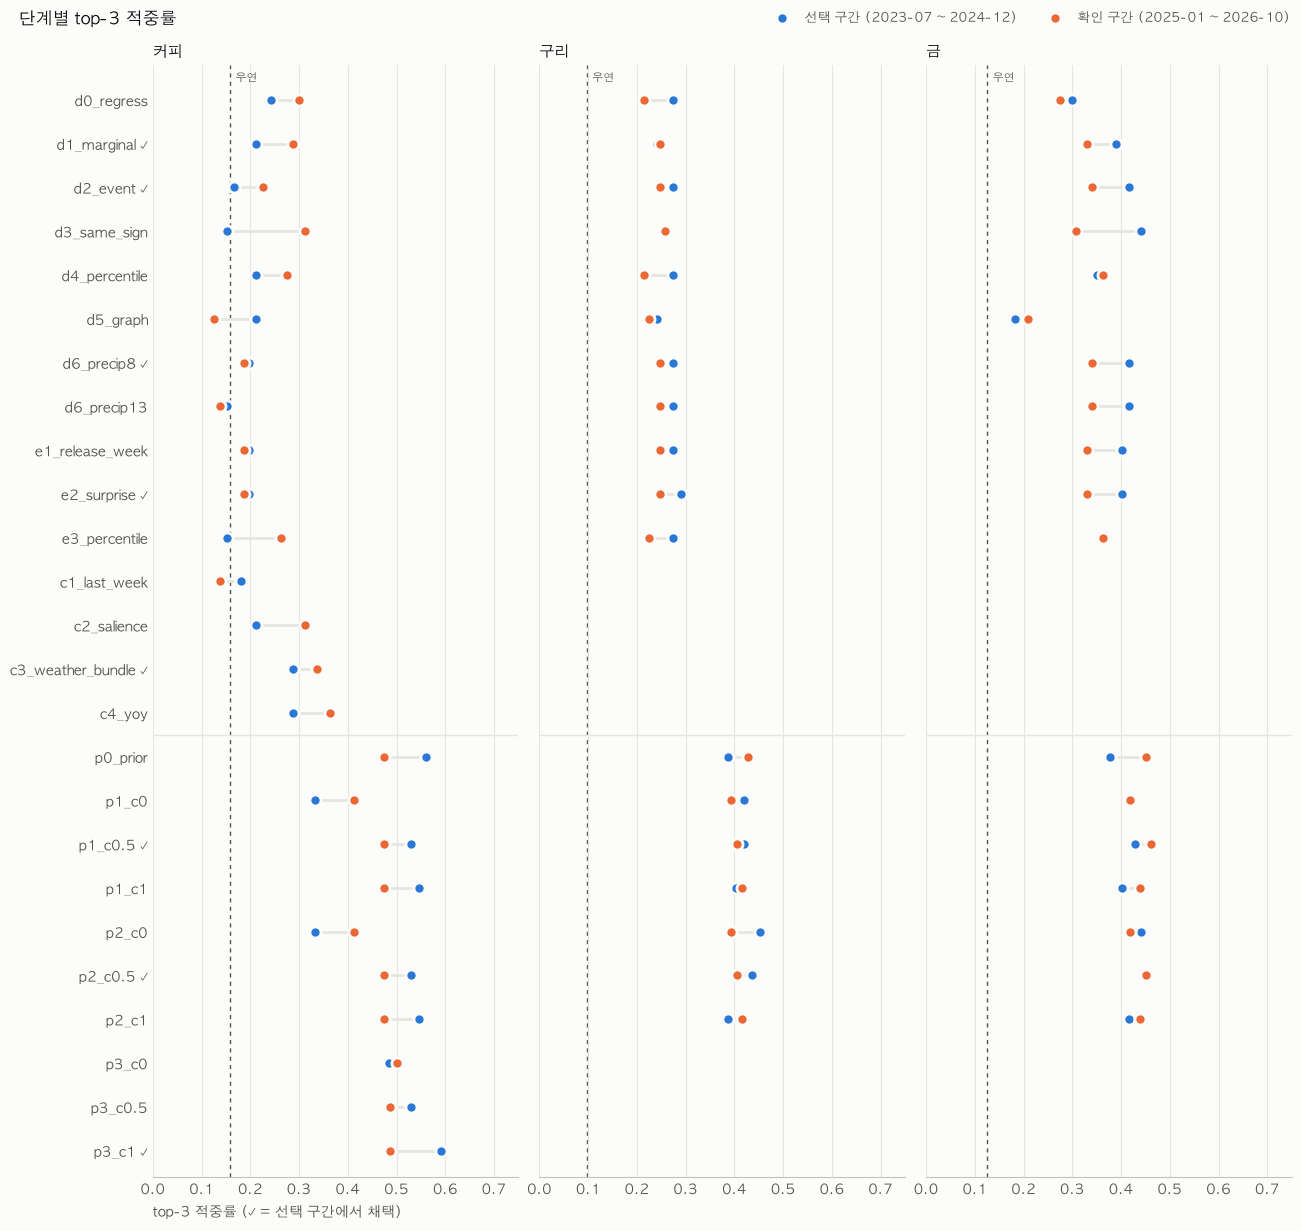

In [14]:
have = {f.name for f in font_manager.fontManager.ttflist}  # 한글 글꼴: 설치된 첫 번째 것
plt.rcParams.update({"font.family": next((f for f in ("AppleGothic", "Malgun Gothic", "NanumGothic") if f in have), "sans-serif"),
                     "axes.unicode_minus": False})
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
SELECT, CONF = "#2a78d6", "#eb6834"

only_coffee = lambda t: t[~t.실험.str.contains("위약")].assign(**{c: lambda d, c=c: d[c].where(d.원자재 == "coffee") for c in ("선택 top3", "확인 top3")})
both = pd.concat([t1, t1b[t1b.실험 != cur_name], only_coffee(t1c[t1c.실험 != cur_name]), t2, t2b[t2b.실험 != "p0_prior"], only_coffee(t2c[t2c.실험 != "p0_prior"])])
names = list(dict.fromkeys(both.실험))
fig, axes = plt.subplots(1, len(SERIES), figsize=(3.9 * len(SERIES) + 1.2, 0.42 * len(names) + 1.7), sharey=True, facecolor=SURFACE, layout="constrained")
for ax, s in zip(np.atleast_1d(axes), SERIES):
    d = both[both.원자재 == s].set_index("실험").reindex(names)
    y = np.arange(len(names))[::-1]
    ax.hlines(y, d["선택 top3"], d["확인 top3"], color=GRID, lw=2, zorder=1)
    ax.scatter(d["선택 top3"], y, s=64, color=SELECT, edgecolor=SURFACE, linewidth=2, zorder=3, label="선택 구간 (2023-07 ~ 2024-12)")
    ax.scatter(d["확인 top3"], y, s=64, color=CONF, edgecolor=SURFACE, linewidth=2, zorder=3, label="확인 구간 (2025-01 ~ 2026-10)")
    chance = baselines[(baselines.원자재 == s) & (baselines.구간 == "확인")]["우연 top3"].iloc[0]
    ax.axvline(chance, color=MUTED, lw=1, ls=(0, (3, 3)), zorder=0)
    ax.annotate("우연", (chance, len(names) - 0.5), xytext=(4, 0), textcoords="offset points", ha="left", va="center", color=MUTED, fontsize=8)
    ax.axhline(len(names) - len(dict.fromkeys(pd.concat([t1, t1b, t1c[~t1c.실험.str.contains("위약")]]).실험)) - 0.5, color=GRID, lw=1)  # 트랙 ①·①′ / ② 경계
    ax.set_yticks(y, [n + (" ✓" if d.채택[n] == "채택" else "") for n in names])
    ax.set_title(SERIES[s], loc="left", color=INK, fontsize=11)
    ax.set_xlim(0, 0.75)
    ax.set_ylim(-0.6, len(names) - 0.2)
    ax.set_facecolor(SURFACE)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, length=0)
first = np.atleast_1d(axes)[0]
fig.legend(*first.get_legend_handles_labels(), frameon=False, loc="outside upper right", ncol=2, labelcolor=MUTED, fontsize=9)
first.set_xlabel("top-3 적중률 (✓ = 선택 구간에서 채택)", color=MUTED, loc="left")
fig.suptitle("단계별 top-3 적중률", x=0.01, ha="left", color=INK)
plt.show()

## 8. 결과 요약과 한계 (2026-11-08 까지의 스냅샷, 2026-11-13 수정 답지, 발표 이력 2026-11-14 수집)

top-3 적중률. 우연 기준선은 커피 0.16, 구리 0.10, 금 0.13.

| | 선택 구간 (세 원자재 평균) | 확인 구간 (평균) | 확인 구간: 커피 / 구리 / 금 |
| --- | --- | --- | --- |
| `d0_regress` (트랙 ① 기준) | 0.27 | 0.26 | 0.30 / 0.21 / 0.28 |
| 트랙 ① 채택 설정 (`d1_marginal` + `d2_event` + `d6_precip8`) | 0.30 | 0.26 | 0.19 / 0.25 / 0.34 |
| `e2_surprise` (트랙 ①′: 채택 설정 + 발표 서프라이즈) | 0.30 | 0.25 | 0.19 / 0.25 / 0.33 |
| `e3_percentile` (e2 + 분위 척도) | 0.26 | 0.28 | 0.26 / 0.23 / 0.36 |
| `p0_prior` (빈도 기준선) | 0.44 | 0.45 | 0.48 / 0.43 / 0.45 |
| `p1_c0.5` (빈도 × 데이터) | 0.46 | 0.45 | 0.48 / 0.40 / 0.46 |
| `p2_c0.5` (빈도 × 서프라이즈 포함 데이터) | 0.47 | 0.44 | 0.48 / 0.40 / 0.45 |

- **데이터만으로는 적중률을 올리지 못했다.** 트랙 ① 에서 채택된 세 단계는 선택 구간 평균을 0.27 → 0.30 으로 올렸지만 단계마다의 차이가 bootstrap 구간 안이고,
  확인 구간에서는 0.26 → 0.26 으로 재현되지 않았다.
- **금만 보면 방향은 일관된다.** 주변 기여와 발표 주 사건으로 선택 0.30 → 0.42, 확인 0.28 → 0.34 다. 다만 확인 구간의 단계별 차이 구간이 0 을 포함한다(+0.05 [−0.03, +0.14], +0.01 [+0.00, +0.03]).
  계단형 변수가 발표 주에 인용되는 정도가 금에서 가장 뚜렷하다(인용 건의 0.61 이 그 주에 값이 바뀜, 기준 확률 0.19 — 1절).
- **커피는 오히려 내려갔다**(확인 0.30 → 0.19). 커피의 계단형 변수는 발표 주 정렬이 약하고(0.24, 기준 확률 0.17), 강수 창을 바꿔도 구간 안의 차이다.
- **그래프로 변수를 고르면 top-3 가 내려간다.** `d5_graph` 는 금에서 선택 −0.23 [−0.34, −0.14], 확인 −0.13 [−0.20, −0.08] — 구간이 0 에서 멀리 벗어난다.
  부모가 몇 개뿐이라 세 자리를 채우지 못한다. top-1 은 구리에서 오른다(선택 0.07 → 0.23, 확인 0.08 → 0.17, 구간은 계산하지 않았다).
- **빈도 기준선이 어떤 데이터 기반 설정보다 높다**(확인 구간 평균 0.45 대 0.19 ~ 0.29). 그 위에 데이터 신호를 섞어도(`p1_c*`) 나아지지 않는다 — 기준선보다 높은 쪽으로 구간이 0 을 벗어난 경우가 없고 확인 구간 평균은 0.45 그대로다.
- **결론: 적중률을 올리는 것은 "무엇이 자주 인용되는가"이고, "이번 주 무엇이 움직였는가"는 그 위에 보태지 못한다.**
  답지의 인용은 그 주의 주간 자료 움직임보다 그 시기에 지배적인 설명(달러·금리·강수)을 따른다.

변수별로 보면(6절) 트랙 ① 이 잡는 것은 시장 변수다 — 달러(구리 0.91, 금 0.96), 금의 2년물·10년물 금리(0.70, 0.86), 커피의 헤알 환율(0.68).
잡지 못하는 것은 세 종류다.
- 발표 지표: CPI·고용은 발표 주에 맞춰도 top-3 에 든 비율이 0.00 이다(금 CPI 17주, 고용 11주). 예상치를 넣어도 그대로다(아래).
- 뉴스 지수: 무역정책 불확실성 지수는 구리·금에서 16 ~ 17주 인용됐지만 0.00 이다.
- 커피의 공급 변수: 미나스 강수 0.19(47주), Conab 생산 추정·베트남 수출 0.00. 강수는 5절에서 다시 본다.

**트랙 ①′ — 발표 서프라이즈 (4절)**

"발표 지표가 안 잡히는 것은 예상치가 입력에 없어서"라는 가설을 확인했다. 발표 지표 12개의 발표일·실제치·시장 예상치(Investing.com, 2008 ~ 2012년부터)를 넣었다.
- **발표 주 정렬은 풀렸다.** 발표 지표 인용 건 가운데 그 주에 실제 발표가 있었던 비율이 구리 0.92, 금 0.95 다(지연 추정으로는 0.54, 0.70).
  그 주 발표가 예상과 달랐던 비율도 0.88, 0.95 다 — 서프라이즈가 0 이라 못 잡는 경우는 드물다.
- **적중률은 그대로다.** `e1_release_week`·`e2_surprise` 의 차이는 모두 ±0.02 이내이고 구간이 0 을 포함한다. 확인 구간 평균 0.26 → 0.25.
  `e2_surprise` 의 채택 표시는 선택 구간 평균 +0.001(구리의 한 주)에서 나온 것이다.
  사전에 계산한 상한(놓친 주의 발표 지표 인용이 전부 맞을 때 확인 구간 금 0.51, 구리 0.34)에 한참 못 미친다(0.33, 0.25).
- **CPI·고용은 여전히 top-3 에 들지 못한다**(6절: `e2_surprise` 에서 금 CPI 0.00, 고용 0.00, 구리도 0.00).
  분위 척도(`e3_percentile`)로 바꾸면 금에서 CPI 0.12, 고용 0.09, GDP 0.80(5주)까지 들지만 달러가 밀려나(금 0.96 → 0.42) 선택 구간 평균이 0.30 → 0.26 으로 내려간다.
- **이유(사후 진단)**: 발표 주들에서 서프라이즈와 그 주 가격의 상관이 약하다 — 금은 CPI −0.17, 고용 −0.13, 구리는 고용 +0.19, CPI −0.05.
  그래서 발표 주의 \|기여\| 중앙값(0.005 ~ 0.06)이 top-3 문턱(0.16 ~ 0.17)을 넘지 못한다. 척도(강건 척도)나 귀속(β·x)을 바꿔도 같다(금 확인 0.32 ~ 0.34, 구리 0.25).
  CPI 서프라이즈는 같은 주 2년물 금리 변화와 +0.23 의 상관이 있다. 영향의 일부가 금리 열에 이미 잡혀 있을 수 있지만 따로 확인하지는 않았다.
- **빈도 사전확률 위에서도 보태지 못한다.** `p2_c0.5` 는 선택 0.47(기준선 0.44), 확인 0.44(기준선 0.45)이고 차이 구간이 모두 0 을 포함한다.
- **결론: 답지의 발표 지표 인용은 그 주의 "놀람의 크기"를 따르지 않는다.** 발표가 있었고 예상과 달랐던 주가 대부분이지만, 주간 가격을 그만큼 움직인 것으로 자료에 나타나지 않는다.
  예상치 부재는 원인이 아니었다. 구리의 중국 산업생산·GDP 서프라이즈는 상관이 0.32 ~ 0.37 로 가장 크지만 답지 인용이 3주씩뿐이다.

**트랙 ①″ — 커피 공급 변수 (5절)**

커피 top-3 적중률(우연 0.16). 위약 = 같은 설정에서 기상 계열만 52주 밀어 넣은 것.

| | 선택 | 확인 | 위약: 선택 / 확인 |
| --- | --- | --- | --- |
| `d6_precip8` (트랙 ① 채택 설정) | 0.20 | 0.19 | |
| `c1_last_week` (강수 = 지난주 강우) | 0.18 | 0.14 | |
| `c2_salience` (+ 점수 = 이례성 분위) | 0.21 | 0.31 | 0.12 / 0.18 |
| `c3_weather_bundle` (+ 기상 표현 묶음) | 0.29 | 0.34 | 0.21 / 0.38 |
| `c4_yoy` (+ 수출·생산 전년 대비) | 0.29 | 0.36 | 0.24 / 0.40 |
| `p0_prior` → `p3_c1` (빈도 × `c3`) | 0.56 → 0.59 | 0.48 → 0.49 | |

- **입력은 답지가 인용한 수치와 대체로 맞는다.** 답지 문구의 "미나스 강우 평년 N%" 12건은 우리 자료의 **지난주** 값과 순위 상관 0.53, 평년 위/아래 일치 0.83 이다(같은 주 값은 0.37, 0.58).
  답지의 기상 인용은 월요일에 나오는 지난주 강우 보고를 따른다.
- **강수와 주간 가격 사이에 안정된 선형 관계는 없다.** 2025-01 이전 522주에서 어떤 강수·기온 표현도 \|ρ\| ≤ 0.08 이고(표준오차 0.044), 수확기와 그 밖으로 나눠도 ≤ 0.16 이며 부호가 엇갈린다.
  그래서 표현만 바꾼 `c1_last_week` 은 오르지 않는다(ρ·x 는 ρ 가 작으면 순위에 들 수 없다).
- **지난주 강우 + 이례성 분위(`c2_salience`)는 실제 기상 정보로 오른다.** 확인 구간 0.14 → 0.31 (+0.17 [+0.07, +0.29]), 같은 설정의 위약보다 0.14 높다([+0.07, +0.21]).
  이 노트북의 데이터 전용 단계 가운데 확인 구간에서 구간이 0 을 벗어난 첫 사례다. 다만 선택 구간에서는 부모 대비 +0.03 [−0.13, +0.21] 로 구분되지 않고(위약 대비 +0.09 [+0.00, +0.21]),
  분위 척도가 헤알 환율을 밀어낸다(인용 주에 top-3 에 든 비율 0.68 → 0.11). 미나스 강수는 0.19 → 0.49, 닥락 강수는 0.00 → 0.45 로 오른다.
- **기상 표현 묶음(`c3`)의 추가 상승은 위약과 구분되지 않는다.** 선택 0.29·확인 0.34 로 더 오르고 선택 구간 규칙으로는 이 단계가 채택되지만, 확인 구간에서 위약이 0.38 로 같은 수준이다(위약 − 실제 +0.04 [−0.06, +0.14]).
  기상 변수가 표현을 여러 장 들고 들어가 순위에 더 자주 드는 효과이고, 커피 답지의 약 3분의 1 이 기상을 인용하기 때문에 그것만으로 적중률이 오른다. 정보로 읽을 수 있는 것은 `c2` 까지다.
- **수출·생산·재고는 그대로다.** `c4_yoy` 의 차이는 +0.00 / +0.03 이고 Conab·베트남 수출·Cecafe 는 여전히 0.00 이다.
  Conab 인용 16주 가운데 Conab 발표가 있었던 주는 5 ~ 6주이고 나머지는 다른 기관(Safras·StoneX·USDA) 전망이나 "풍작 전망" 서사다 — 주간 자료에 그 주의 사건이 없다.
- **빈도 기준선에는 여전히 못 미치고(0.31 ~ 0.36 대 0.48), 섞어도 보태지 못한다**(`p3_c1` 확인 +0.01 [−0.03, +0.05]).
- 세 원자재 평균으로 보면 커피를 `c2_salience` 로 바꿨을 때 확인 구간 0.26 → 0.30 이다(구리 0.25, 금 0.34 는 그대로).

한계
- 트랙 ①″ 의 표현(지난주 강우, 예보 대용, 전년 대비)은 답지 문구를 읽고 골랐다 — 선택·확인 두 구간의 문구를 모두 봤다. "다음 주 강우"는 미래 값이라 사후 설명에만 쓸 수 있다.
- 강수는 NASA 격자 한 점(미나스 21°S 45°W)이고 답지가 인용하는 주 단위 보고와 집계 범위가 다르다. 건기에는 평년값이 작아 평년 대비 %가 크게 흔들린다. 강수 자료는 2026-10-12 까지라 답지의 마지막 두 주(10-18, 10-25)는 하루치 값과 앞값이다.
- 위약 대조는 기상 계열에만 했다. 분위 척도 자체의 효과(`c2` 가 `c1` 보다 높은 것)에는 기상 정보와 척도 변경이 섞여 있다 — 기상 몫은 위약 대비 차이로 읽는다.
- 채택 규칙이 선택 구간 평균의 크기만 본다. 채택된 단계들의 차이(+0.00 ~ +0.01)는 표준오차(주 수 62 ~ 91 에서 약 0.05)보다 작다 — 채택 표시를 "효과가 있다"로 읽지 않는다.
- 두 구간 모두 앞 분석에서 전체 기간 합계로 본 적이 있다. 사전 점검(전체 기간·전체 표본 계수)에서 본 금 0.41 은 규약대로 돌린 확인 구간에서 0.34 다.
- `d3_same_sign` 은 그 주 가격의 방향을 쓴다(사후 설명). `d4_percentile` 의 분위는 전체 기간에서 계산한다.
- 트랙 ① 의 발표 주는 지연 추정치 기준이라 한 주 어긋나는 경우가 있다(±1주로 보면 구리 0.82, 금 0.87). 트랙 ①′ 은 실제 발표일(UTC 날짜)을 쓴다.
- 예상치는 Investing.com 한 곳의 집계다(다른 컨센서스와 다를 수 있다). PCE(금 8주 인용)와 연준 금리 결정은 넣지 않았다.
- 서프라이즈를 표준편차로 나누면 고용은 2020년 몇 건이 척도를 정한다(표준편차 766천 명, 중앙절대값 기준 78천 명). 강건 척도로 바꿔 본 것은 결과를 본 뒤의 확인이다.
- `e1_release_week` 은 발표 주만 옮긴 것이 아니다 — 크기도 "지연 반영 값의 변화"에서 "직전 발표 대비 실제치 변화"로 바뀐다.
- 빈도 사전확률의 동점은 열 순서로 가른다. 처음 26주는 사전확률을 채우는 데만 쓰고 채점하지 않았다.
- 계수와 그래프는 2025-01 이전 주로 적합했지만 답지 기간(2023 ~ 2024)은 포함한다.

## 리더보드 내보내기

위 표와 같은 귀속·채점을 `analysis/notebook_board.py` 형식으로 쓴다. 올리기: `uv run python tools/log_causal_leaderboard.py --path <출력 폴더>`. 이 노트북의 평가 조건(`protocol`)은 `fit_lt_2025` 라 다른 조건의 run 과 같은 순위에 넣지 않는다.


In [15]:
from notebook_board import export

PHASE = {"선택": "selection", "확인": "confirmation"}
runs = {}
for tr, prior in [(track1, False), (track1b, False), (track1c, False), (track2, True), (track2b, True), (track2c, True)]:
    for n, (parent, get, adopted) in tr.items():
        runs.setdefault(n, (parent, get, adopted, prior))  # 같은 이름은 같은 점수 함수다(트랙마다 기준 줄이 반복된다)
rows = [dict(name=n, phase=PHASE[per], series=s, contrib=get(s), X=panel(s)[0], key=cut(keys[s]), parent=parent or "",
             axis="prior" if prior else "data", uses_answer_key=prior)  # 트랙 ② 는 답지 인용 빈도를 쓴다 — 인과 방법 순위와 따로 본다
        for n, (parent, get, adopted, prior) in runs.items() for s in SERIES for per, cut in PERIODS.items()]
export("attribution", "ATTRIBUTION-ABLATION.ipynb", rows, "fit_lt_2025",
       specs={n: dict(adopted=adopted, **({k: v for k, v in configs[n].items()} if n in configs else {})) for n, (_, _, adopted, _) in runs.items()})


exported 168 rows, 52 comparisons → /Users/sonet/Desktop/01_riotinto/data/07_reporting/causal_notebooks/attribution/b9ff93a4d62c39faac11


PosixPath('/Users/sonet/Desktop/01_riotinto/data/07_reporting/causal_notebooks/attribution/b9ff93a4d62c39faac11')